Все результаты сохраняются в: DEEP_DIVE_4CONN_CUDA_20261029_174951

СЧИТАЕМ (CUDA 4-conn): Плотность = 10.0%, Сигма = 2.0, Лямбда = 3.0
     Шаг |  density |    P_inf |  Perimeter | Max_Size | Time(s)
-----------------------------------------------------------------
  250000 |    0.099 |    0.956 |      442.0 |      950 |  2927.5


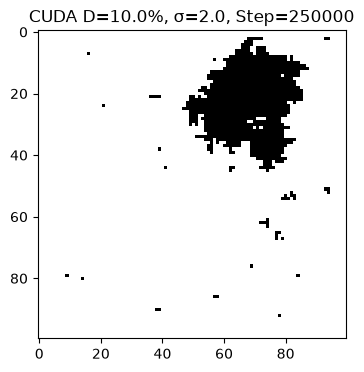

KeyboardInterrupt: 

In [1]:
# ============================================================
# DEEP_DIVE_4CONN_CUPY_GIF: 4-СВЯЗНОСТЬ НА GPU С GIF И REM
# ============================================================

# REM: Импортируем библиотеку numpy для работы с массивами на CPU.
# REM: Она нужна для сохранения файлов на диск (формат .npy).
import numpy as np

# REM: Импортируем cupy. Это библиотека для вычислений на GPU.
# REM: Синтаксис почти как у numpy, но работает в сотни раз быстрее на видеокарте.
import cupy as cp

# REM: Импортируем cupyx.scipy.ndimage.label. 
# REM: Это GPU-аналог функции поиска кластеров (связанных областей).
# REM: Без нее 4-связность на GPU посчитать невозможно.
from cupyx.scipy.ndimage import label as cp_label

# REM: Импорт библиотеки для рисования графиков.
import matplotlib

# REM: Включаем фоновый режим 'Agg'.
# REM: Это значит, что графики не будут открываться в отдельных окнах,
# REM: а будут просто сохраняться в файлы.
matplotlib.use('Agg') 

# REM: Импорт модуля pyplot для создания картинок.
import matplotlib.pyplot as plt

# REM: Импорт imageio для сборки GIF-анимаций из сохраненных картинок.
import imageio.v2 as imageio

# REM: Импорт для записи таблиц с результатами в формате CSV.
import csv

# REM: Импорт для замера времени (чтобы знать, сколько длится расчет).
import time

# REM: Импорт для работы с файловой системой (создание папок, проверка путей).
import os

# REM: Импорт для генерации даты и времени (для уникальных имен папок).
from datetime import datetime

# REM: Импорт для вывода картинок прямо в окно Jupyter.
from IPython.display import display, Image as IPImage

# ------------------------------------------------------------
# REM: БЛОК 1. НАСТРОЙКА ПАПОК С МЕТКОЙ ВРЕМЕНИ
# ------------------------------------------------------------

# REM: Генерируем уникальную метку времени.
# REM: Пример результата: "20261029_154500" (год, месяц, день, час, минута, секунда).
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# REM: Создаем имя главной папки, приклеивая метку времени.
# REM: Это нужно, чтобы каждый запуск создавал новую папку и не перезаписывал старые данные.
output_dir = f"DEEP_DIVE_4CONN_CUDA_{timestamp}"

# REM: Формируем путь к подпапке для CSV-таблиц.
csv_dir = os.path.join(output_dir, "csv")

# REM: Формируем путь к подпапке для картинок (PNG).
png_dir = os.path.join(output_dir, "png")

# REM: Формируем путь к подпапке для чекпоинтов (сохранений состояния сетки).
ckpt_dir = os.path.join(output_dir, "checkpoints")

# REM: Физически создаем все папки.
# REM: exist_ok=True не даст программе упасть с ошибкой, если папка уже существует.
os.makedirs(output_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)
os.makedirs(png_dir, exist_ok=True)
os.makedirs(ckpt_dir, exist_ok=True)

# REM: Выводим в консоль сообщение о том, куда сохраняются данные.
print(f"Все результаты сохраняются в: {output_dir}", flush=True)

# ------------------------------------------------------------
# REM: БЛОК 2. ФИЗИЧЕСКИЕ ПАРАМЕТРЫ СИМУЛЯЦИИ
# ------------------------------------------------------------

# REM: L — размер решетки (LxL узлов).
# REM: 100 означает матрицу 100x100, то есть 10 000 узлов.
# REM: Это стандарт для быстрых тестов, который мы использовали во всех прошлых прогонах.
L = 100

# REM: STEPS — количество шагов во внешнем цикле.
# REM: ВАЖНО: Внутри цикла мы делаем по 5 реальных шагов Метрополиса за раз.
# REM: 500 000 * 5 = 2 500 000 реальных шагов. Это нужно для глубокого расчета.
STEPS = 500_000 

# REM: beta — обратная температура (1/kT).
# REM: Отвечает за уровень случайного шума.
# REM: 1.0 — стандартное значение, которое мы использовали.
beta = 1.0

# REM: lam (Лямбда) — сила агрегации.
# REM: Чем выше значение, тем сильнее узлы притягиваются друг к другу.
# REM: 3.0 — сильное притяжение, при котором образуются плотные кластеры.
lam = 3.0          

# REM: POINTS — список кортежей (tuples), которые содержат наши "вкусные" точки.
# REM: Формат кортежа: (Плотность, Сигма).
# REM: (0.10, 2.0) — 10% плотность, Сигма 2.0 (точка минимума периметра).
# REM: (0.10, 2.5) — 10% плотность, Сигма 2.5 (точка скачка периметра).
# REM: (0.50, 1.5) — 50% плотность, Сигма 1.5 (начало образования геля).
# REM: (0.50, 2.0) — 50% плотность, Сигма 2.0 (стабилизация геля).
POINTS = [
    (0.10, 2.0),  
    (0.10, 2.5),  
    (0.50, 1.5),  
    (0.50, 2.0)   
]

# REM: Формируем полный путь к главному CSV-файлу для записи результатов.
csv_file = os.path.join(csv_dir, "deep_dive_4conn_cuda.csv")

# REM: Проверяем, существует ли уже этот файл.
# REM: Если файла нет, создаем его и записываем заголовки колонок.
if not os.path.exists(csv_file):
    # REM: Открываем файл в режиме записи ('w').
    with open(csv_file, 'w', newline='') as f:
        # REM: Создаем объект writer для записи строк.
        writer = csv.writer(f)
        # REM: Записываем строку с названиями колонок.
        writer.writerow(['p_init', 'lam', 'sigma', 'step', 'density', 'P_inf', 'perimeter', 'max_size'])

# ------------------------------------------------------------
# REM: БЛОК 3. ФИЗИЧЕСКИЕ ФУНКЦИИ НА GPU (CUPY)
# ------------------------------------------------------------

def find_clusters_periodic_cp(grid_cp):
    # REM: Функция для поиска кластеров на GPU с учетом периодических границ (тор).
    
    # REM: cp.pad добавляет рамку вокруг матрицы.
    # REM: mode='wrap' означает, что верхний край соединяется с нижним, а левый с правым.
    padded = cp.pad(grid_cp, pad_width=1, mode='wrap')
    
    # REM: Создаем структуру для поиска 4-связности (соседи сверху, снизу, слева, справа).
    structure = cp.array([[0,1,0],[1,1,1],[0,1,0]], dtype=cp.int32)
    
    # REM: cp_label — это аналог scipy.ndimage.label, но работает на видеокарте.
    # REM: Он возвращает матрицу с номерами кластеров (labeled) и их количество (n).
    labeled, n = cp_label(padded, structure=structure)
    
    # REM: Убираем добавленную рамку, чтобы вернуть исходный размер матрицы.
    labeled = labeled[1:-1, 1:-1]
    
    # REM: cp.bincount считает, сколько раз встречается каждый номер кластера (то есть его размер).
    sizes = cp.bincount(labeled.ravel())
    
    # REM: Обнуляем фон (0), так как нас интересуют только кластеры из единиц.
    sizes[0] = 0
    
    return labeled, sizes

def calculate_perimeter_cp(grid_cp):
    # REM: Функция для подсчета общего периметра системы на GPU.
    
    # REM: cp.roll сдвигает матрицу на 1 элемент. Это быстро и учитывает зацикливание.
    right = cp.roll(grid_cp, 1, axis=1)
    left = cp.roll(grid_cp, -1, axis=1)
    up = cp.roll(grid_cp, 1, axis=0)
    down = cp.roll(grid_cp, -1, axis=0)
    
    # REM: Суммируем места, где занятый узел (1) соседствует с пустым (0).
    p = cp.sum((grid_cp == 1) & (right == 0))
    p += cp.sum((grid_cp == 1) & (left == 0))
    p += cp.sum((grid_cp == 1) & (up == 0))
    p += cp.sum((grid_cp == 1) & (down == 0))
    
    # REM: Возвращаем периметр как целое число (переводим с GPU на CPU).
    return int(p)

def action_cp(grid_cp, lam, sigma):
    # REM: Функция для расчета полной энергии системы на GPU.
    
    # REM: Получаем размеры всех кластеров.
    _, sizes = find_clusters_periodic_cp(grid_cp)
    
    # REM: Энергия агрегации. Знак минус: чем больше кластер, тем ниже энергия (выгоднее).
    S_bulk = -lam * cp.sum(sizes**2)
    
    # REM: Энергия натяжения. Знак плюс: чем больше периметр, тем выше энергия (невыгодно).
    S_surface = sigma * calculate_perimeter_cp(grid_cp)
    
    # REM: Возвращаем суммарную энергию.
    return S_bulk + S_surface

def metropolis_step_swap_cp(grid_cp, lam, sigma, beta=1.0):
    # REM: Один шаг алгоритма Метрополиса.
    
    # REM: Находим координаты всех занятых (1) и пустых (0) узлов на GPU.
    occupied = cp.argwhere(grid_cp == 1)
    empty = cp.argwhere(grid_cp == 0)
    
    # REM: Защита от зависания, если сетка пустая или полностью заполнена.
    if len(occupied) == 0 or len(empty) == 0: return False
    
    # REM: Выбираем случайный индекс занятого и случайный индекс пустого узла.
    idx_occ = cp.random.randint(0, len(occupied))
    idx_empty = cp.random.randint(0, len(empty))
    
    # REM: Получаем координаты этих узлов.
    i1, j1 = occupied[idx_occ]
    i2, j2 = empty[idx_empty]

    # REM: Считаем старую энергию.
    S_old = action_cp(grid_cp, lam, sigma)
    
    # REM: Меняем узлы местами (занятый становится пустым, пустой — занятым).
    grid_cp[i1, j1] = 0
    grid_cp[i2, j2] = 1
    
    # REM: Считаем новую энергию.
    S_new = action_cp(grid_cp, lam, sigma)
    
    # REM: Вычисляем разницу энергий.
    delta_S = S_new - S_old

    # REM: Если энергия упала (delta_S <= 0), принимаем шаг.
    # REM: Или принимаем с вероятностью exp(-beta * delta_S) (термофлуктуации).
    if delta_S <= 0 or cp.random.rand() < cp.exp(-beta * delta_S):
        return True
    else:
        # REM: Если не приняли, возвращаем узлы на место.
        grid_cp[i1, j1] = 1
        grid_cp[i2, j2] = 0
        return False

def measure_cp(grid_cp):
    # REM: Функция для измерения характеристик системы.
    
    # REM: Получаем размеры кластеров.
    labeled, sizes = find_clusters_periodic_cp(grid_cp)
    sizes_nonzero = sizes[sizes > 0]
    
    # REM: Если кластеров нет, возвращаем None.
    if len(sizes_nonzero) == 0: return None
    
    # REM: P_inf — доля частиц в самом большом кластере.
    P_inf = float(sizes_nonzero.max() / cp.sum(sizes_nonzero))
    
    # REM: Реальная плотность системы.
    density = float(cp.mean(grid_cp))
    
    # REM: Общий периметр.
    perimeter = calculate_perimeter_cp(grid_cp)
    
    # REM: Абсолютное число частиц в самом большом кластере.
    max_size = int(sizes_nonzero.max())
    
    # REM: Возвращаем словарь с результатами.
    return {'density': density, 'P_inf': P_inf, 'perimeter': perimeter, 'max_size': max_size}

# ------------------------------------------------------------
# REM: БЛОК 4. ГЛАВНЫЙ ЦИКЛ ЗАПУСКА
# ------------------------------------------------------------

# REM: Начинаем перебор по списку POINTS.
for p, sigma in POINTS:
    # REM: Формируем пути к файлам чекпоинтов для текущей точки.
    ckpt_grid_file = os.path.join(ckpt_dir, f"grid_p{p}_s{sigma}.npy")
    ckpt_step_file = os.path.join(ckpt_dir, f"step_p{p}_s{sigma}.npy")
    
    # REM: По умолчанию начинаем с нулевого шага.
    start_step = 0
    grid_cp = None
    
    # REM: Создаем пустой список для хранения путей к картинкам (для будущего GIF).
    frames = [] 
    
    # REM: Проверяем, есть ли сохранения на диске.
    if os.path.exists(ckpt_grid_file) and os.path.exists(ckpt_step_file):
        # REM: Загружаем сетку с диска (на CPU).
        grid_np = np.load(ckpt_grid_file)
        # REM: Переносим сетку на видеокарту.
        grid_cp = cp.asarray(grid_np)
        # REM: Загружаем сохраненный шаг.
        start_step = int(np.load(ckpt_step_file)[0])
        print(f"\n[RESTART] Плотность {p*100}%, Сигма {sigma}. Восстанавливаем с шага {start_step*5}...", flush=True)
    else:
        # REM: Если сохранений нет, создаем случайную сетку прямо на GPU.
        grid_cp = cp.random.rand(L, L) < p
        # REM: Превращаем логический массив (True/False) в целые числа (1/0).
        grid_cp = grid_cp.astype(cp.int32)

    # REM: Выводим заголовок таблицы в консоль.
    print("\n" + "="*65, flush=True)
    print(f"СЧИТАЕМ (CUDA 4-conn): Плотность = {p*100}%, Сигма = {sigma}, Лямбда = {lam}", flush=True)
    print("="*65, flush=True)
    print(f"{'Шаг':>8} | {'density':>8} | {'P_inf':>8} | {'Perimeter':>10} | {'Max_Size':>8} | {'Time(s)':>7}", flush=True)
    print("-" * 65, flush=True)

    # REM: Засекаем время начала расчетов.
    t0 = time.time()
    
    # REM: Запускаем основной цикл шагов.
    for step in range(start_step, STEPS):
        # REM: Внутренний цикл делает 5 шагов за раз (для ускорения).
        for _ in range(5):
            metropolis_step_swap_cp(grid_cp, lam, sigma, beta)
        
        # REM: Считаем реальный номер шага.
        real_step = step * 5
        
        # REM: Каждые 250 000 реальных шагов делаем замер и сохраняем данные.
        if real_step % 250_000 == 0 and real_step > 0:
            # REM: Измеряем характеристики.
            m = measure_cp(grid_cp)
            # REM: Замеряем затраченное время.
            elapsed = time.time() - t0
            
            # REM: Дописываем строку с результатами в CSV-файл.
            with open(csv_file, 'a', newline='') as f:
                writer = csv.writer(f)
                writer.writerow([p, lam, sigma, real_step, m['density'], m['P_inf'], m['perimeter'], m['max_size']])
            
            # REM: Печатаем строку в консоль.
            print(f"{real_step:>8} | {m['density']:>8.3f} | {m['P_inf']:>8.3f} | {m['perimeter']:>10.1f} | {m['max_size']:>8d} | {elapsed:>7.1f}", flush=True)
            
            # REM: Сохраняем текущее состояние сетки на диск (переводим на CPU).
            np.save(ckpt_grid_file, cp.asnumpy(grid_cp))
            np.save(ckpt_step_file, np.array([step]))
            
            # REM: Создаем картинку текущего состояния.
            fig, ax = plt.subplots(figsize=(4, 4))
            ax.imshow(cp.asnumpy(grid_cp), cmap='binary', interpolation='nearest')
            ax.set_title(f'CUDA D={p*100}%, σ={sigma}, Step={real_step}')
            
            # REM: Сохраняем картинку в папку.
            img_path = os.path.join(png_dir, f"C_D{p}_S{sigma}_step{real_step}.png")
            plt.savefig(img_path, dpi=100, bbox_inches='tight')
            # REM: Закрываем фигуру, чтобы не забивать память.
            plt.close(fig)
            
            # REM: Добавляем путь к картинке в список для GIF.
            frames.append(img_path)
            
            # REM: Показываем картинку прямо в блокноте Jupyter.
            display(IPImage(filename=img_path))

    # REM: После завершения цикла делаем финальный замер.
    m = measure_cp(grid_cp)
    # REM: Записываем финальную точку в CSV.
    with open(csv_file, 'a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([p, lam, sigma, STEPS*5, m['density'], m['P_inf'], m['perimeter'], m['max_size']])
    
    # REM: СОБИРАЕМ GIF В КОНЦЕ КАЖДОЙ ТОЧКИ.
    # REM: Проверяем, есть ли сохраненные кадры.
    if frames:
        print(f"Собираем GIF для D={p*100}%, σ={sigma}...", flush=True)
        # REM: Загружаем все картинки из списка.
        images = [imageio.imread(f) for f in frames]
        # REM: Формируем путь к GIF-файлу.
        gif_path = os.path.join(output_dir, f"anim_D{p}_S{sigma}.gif")
        # REM: Склеиваем картинки в GIF. fps=2 означает 2 кадра в секунду.
        imageio.mimsave(gif_path, images, fps=2)
        print(f"GIF сохранен: {gif_path}", flush=True)
    
    # REM: Удаляем файлы чекпоинтов, так как точка полностью завершена.
    if os.path.exists(ckpt_grid_file): os.remove(ckpt_grid_file)
    if os.path.exists(ckpt_step_file): os.remove(ckpt_step_file)
    
    print(f"ТОЧКА ЗАВЕРШЕНА.", flush=True)

# REM: Выводим финальное сообщение о завершении всех расчетов.
print(f"\nВСЕ 4 ТОЧКИ ГОТОВЫ! GIF и данные в {output_dir}.", flush=True)